Deep Neural Network From Scratch in Python:

Unlike our previous two-layer model which used hardcoded variables like $W^{[1]}$ and $W^{[2]}$, this generalized implementation uses a Python dictionary and a list of layer dimensions ($layer\_dims$). This lets us dynamically build any number of hidden layers ($k$ layers).


In [18]:
import numpy as np

def init_layers(layer_dims):
    parameters = {}
    L = len(layer_dims)
    
    for l in range(1, L):
        # Initialisation de He (recommandée pour ReLU) : sqrt(2 / n_in)
        parameters['W' + str(l)] = np.random.randn(layer_dims[l], layer_dims[l-1]) * np.sqrt(2.0 / layer_dims[l-1])
        parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))
        
    return parameters

Activation Functions and HelpersThe helper functions like ReLU, ReLU derivative, softmax, and one-hot encoding remain functionally identical to our two-layer script. The mathematical operations per layer are structurally identical regardless of how deep the network goes, mapping inputs to $Z^{[l]}$ and $A^{[l]}$.

In [19]:
def ReLU(Z):
    return np.maximum(Z, 0)

def ReLU_deriv(Z):
    return Z > 0

def softmax(Z):
    exp_Z = np.exp(Z - np.max(Z, axis=0, keepdims=True))
    return exp_Z / np.sum(exp_Z, axis=0, keepdims=True)

def one_hot(Y):
    one_hot_Y = np.zeros((Y.size, Y.max() + 1))
    one_hot_Y[np.arange(Y.size), Y] = 1
    return one_hot_Y.T

Forward PropagationIn the two-layer case, we wrote explicit code blocks for the first and second layers ($Z^{[1]}, A^{[1]}, Z^{[2]}, A^{[2]}$). Here, we replace those fixed steps with a loop that iterates through all hidden layers from $1$ to $L-1$, stores intermediate caches dynamically, and applies softmax on the final layer $L$.

In [20]:
def forward_prop_deep(X, parameters):
    caches = []
    A = X
    L = len(parameters) // 2
    for l in range(1, L):
        A_prev = A
        W = parameters['W' + str(l)]
        b = parameters['b' + str(l)]
        Z = np.dot(W, A_prev) + b
        A = ReLU(Z)
        caches.append((Z, A_prev, W, b))
    W_last = parameters['W' + str(L)]
    b_last = parameters['b' + str(L)]
    Z_last = np.dot(W_last, A) + b_last
    AL = softmax(Z_last)
    caches.append((Z_last, A, W_last, b_last))
    return AL, caches

Backward PropagationInstead of writing out separate manual formulas for layer two and layer one backpropagation ($dZ^{[2]}, dW^{[2]}, dZ^{[1]}, dW^{[1]}$), this generalized version uses a reversed loop over the stored caches. It starts at the output layer $L$ and loops backwards through the hidden layers using the chain rule.

In [21]:
def backward_prop_deep(AL, Y, caches):
    grads = {}
    L = len(caches)
    m = AL.shape[1]
    one_hot_Y = one_hot(Y)
    Z_L, A_prev_L, W_L, b_L = caches[L-1]
    dZ = AL - one_hot_Y
    grads["dW" + str(L)] = (1 / m) * np.dot(dZ, A_prev_L.T)
    grads["db" + str(L)] = (1 / m) * np.sum(dZ, axis=1, keepdims=True)
    dZ_prev = dZ
    for l in reversed(range(L - 1)):
        Z_l, A_prev_l, W_l, b_l = caches[l]
        W_next = caches[l+1][2]
        dZ_prev = np.dot(W_next.T, dZ_prev) * ReLU_deriv(Z_l)
        grads["dW" + str(l+1)] = (1 / m) * np.dot(dZ_prev, A_prev_l.T)
        grads["db" + str(l+1)] = (1 / m) * np.sum(dZ_prev, axis=1, keepdims=True)
    return grads

Parameter Updates and Training LoopThe parameter update step loops through all $L$ layers dynamically using $W^{[l]} := W^{[l]} - \alpha dW^{[l]}$ instead of updating $W^{[1]}$ and $W^{[2]}$ individually. The overall training loop structure remains similar, calling our generalized forward, backward, and update functions iteratively.

In [22]:
def update_params_deep(parameters, grads, alpha):
    L = len(parameters) // 2
    for l in range(1, L + 1):
        parameters['W' + str(l)] -= alpha * grads['dW' + str(l)]
        parameters['b' + str(l)] -= alpha * grads['db' + str(l)]
    return parameters

def get_predictions(AL):
    return np.argmax(AL, 0)

def get_accuracy(predictions, Y):
    return np.sum(predictions == Y) / Y.size

def gradient_descent_deep(X, Y, layer_dims, alpha, iterations):
    parameters = init_layers(layer_dims)
    for i in range(iterations):
        AL, caches = forward_prop_deep(X, parameters)
        grads = backward_prop_deep(AL, Y, caches)
        parameters = update_params_deep(parameters, grads, alpha)
        if i % 10 == 0:
            predictions = get_predictions(AL)
            acc = get_accuracy(predictions, Y)
            print(f"Iteration {i} - Accuracy: {acc * 100:.2f}%")
    return parameters

Testing and Comparing Architectures ($k$ layers vs 2 layers)To evaluate our generalized model and compare its performance against the 2-layer architecture with different hyperparameters (such as various hidden layer sizes or learning rates), we can run both models and plot their accuracy curves on the same graph using matplotlib.

In [23]:
import pandas as pd
import numpy as np


data = pd.read_csv('train.csv')
data = np.array(data)

m, n = data.shape


np.random.shuffle(data)


data_test = data[0:1000].T 
Y_test = data_test[0]
X_test = data_test[1:n]


data_train = data[1000:m].T
Y_train = data_train[0]
X_train = data_train[1:n]


X_train = X_train / 255.0
X_test = X_test / 255.0

Training: 2 Layers (10 units)...
Training: Deep (128, 64 units)...
Training: Wide & Deep (256, 128, 64 units)...


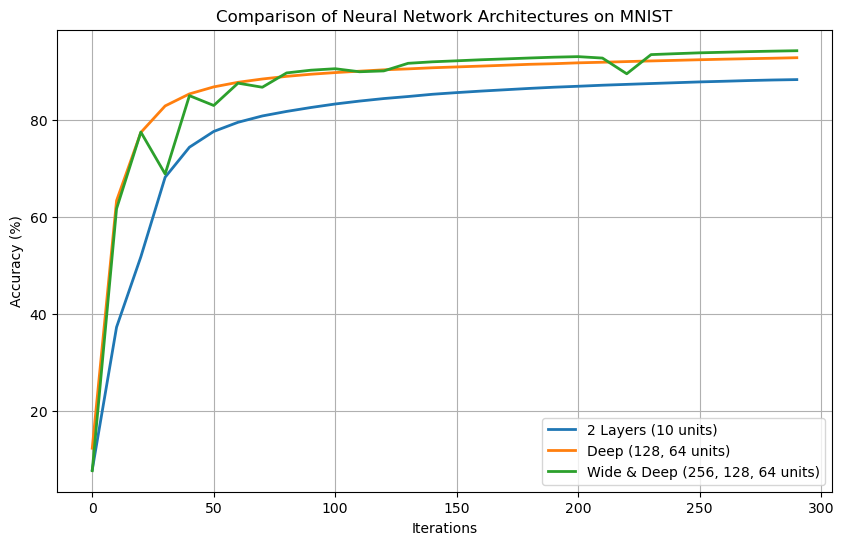

In [24]:

import matplotlib.pyplot as plt

architectures = {
    "2 Layers (10 units)": [784, 10, 10],
    "Deep (128, 64 units)": [784, 128, 64, 10],
    "Wide & Deep (256, 128, 64 units)": [784, 256, 128, 64, 10]
}


def train_and_track(X, Y, layer_dims, alpha, iterations):
    parameters = init_layers(layer_dims)
    accuracies = []
    
    for i in range(iterations):
        AL, caches = forward_prop_deep(X, parameters)
        grads = backward_prop_deep(AL, Y, caches)
        parameters = update_params_deep(parameters, grads, alpha)
        
        if i % 10 == 0:
            preds = get_predictions(AL)
            acc = get_accuracy(preds, Y)
            accuracies.append(acc)
            
    return accuracies

iterations = 300
alpha = 0.1
history = {}

for name, dims in architectures.items():
    print(f"Training: {name}...")
    history[name] = train_and_track(X_train, Y_train, dims, alpha, iterations)

# 4. Plot the comparison graph
plt.figure(figsize=(10, 6))
for name, accs in history.items():
    plt.plot(range(0, iterations, 10), [a * 100 for a in accs], label=name, linewidth=2)

plt.title("Comparison of Neural Network Architectures on MNIST")
plt.xlabel("Iterations")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

In deep neural networks, the choice of weight initialization dictates how information flows through the architecture during forward and backward propagation. For a network with $L$ layers, the pre-activation at layer $l$ is defined as:$$Z^{[l]} = W^{[l]} A^{[l-1]} + b^{[l]}$$When standard small random initializations (such as multiplying by $0.01$) are used, the variance of the activations decreases exponentially as the depth increases. This causes the gradients computed via the chain rule, $\frac{\partial L}{\partial W^{[l]}}$, to vanish in the deeper layers. Combined with the Rectified Linear Unit ($\text{ReLU}$) activation function defined as:$$\text{ReLU}(Z) = \max(0, Z)$$any neuron whose pre-activation falls below zero receives a local derivative of zero ($\text{ReLU}'(Z) = 0$), causing it to become a dead neuron that permanently stops learning. This mathematical bottleneck explains why naive deep architectures remain stagnant at baseline random accuracy (approx. $11\%$ for a 10-class problem).To resolve this issue, He initialization scales the variance of the weights based on the fan-in (number of input connections $n_{in}$) of the layer:$$W^{[l]} \sim \mathcal{N}\left(0, \frac{2}{n_{in}}\right)$$This maintains a stable variance across layers, allowing gradients to propagate effectively and enabling deep $k$-layer networks to converge successfully.